# Défi NLP medRxiv, projet 1, prédiction de la discipline
## Script 1, méthodes historiques (machine learning)

**Contexte.** medRxiv est une plateforme de prépublication (*preprints*) en sciences de la santé. Les chercheurs y déposent leurs articles avant leur publication dans une revue, et choisissent eux-mêmes la discipline de leur travail au moment du dépôt. Prédire automatiquement cette discipline à partir de l'abstract permettrait de suggérer une catégorie aux auteurs, de vérifier les choix faits et de mieux classer les preprints. 
Ce script utilise des méthodes classiques (TF-IDF et modèles de machine learning).

**Objectif.** Prédire la discipline d'un preprint (`category_grp`, 16 modalités) à partir de son abstract. Le fichier de test ne contient que `ID` et `abstract`, donc seul l'abstract est utilisé.


   Plan:
 1. exploration des données
 2. nettoyage et prétraitement (balises, doublons, tokenisation, minuscules, mots vides, lemmatisation)
 3. stratégie de validation
 4. représentations du texte et réduction de dimension (sac de mots, TF-IDF, n-grammes, LSA, chi2)
 5. modèles (déséquilibre des classes, 5 modèles de classification, super-learner)
 6. évaluation et analyse des erreurs
 7. prédiction du fichier de test
 8. conclusion


In [ ]:
#installation des bibliothèques
import sys
%pip install -q spacy spacy-lookups-data imbalanced-learn

In [ ]:
import re
import html
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fichier_entrainement = "ClassificationsMedicales_AbstractsTrainingSet.csv.gz"   #abstracts étiquetés
fichier_test = "ClassificationsMedicales_AbstractsTestSet.csv.gz"               #abstracts à classer
fichier_sortie = "predictions_projet1.csv"                                      #fichier rendu (ID, pred)
cible = "category_grp"   #nom de la variable à prédire dans le fichier 

## 1. exploration des données
Taille des données, équilibre des 16 disciplines, doublons, longueur des textes, et mêmes vérifications sur le fichier de test. Les fichiers sont séparés par des points-virgules.

Entraînement : (10958, 7) | test : (1940, 2) | valeurs manquantes (entraînement) : 0

16 disciplines (regroupant 51 disciplines déclarées), de 324 à 1060 abstracts
doi répétés : 1626 | abstracts répétés : 1634 | abstracts identiques avec 2 disciplines : 7
Mots par abstract : médiane 264.0 | min 15 | max 1488
Test : 643 abstracts vides (33 %)


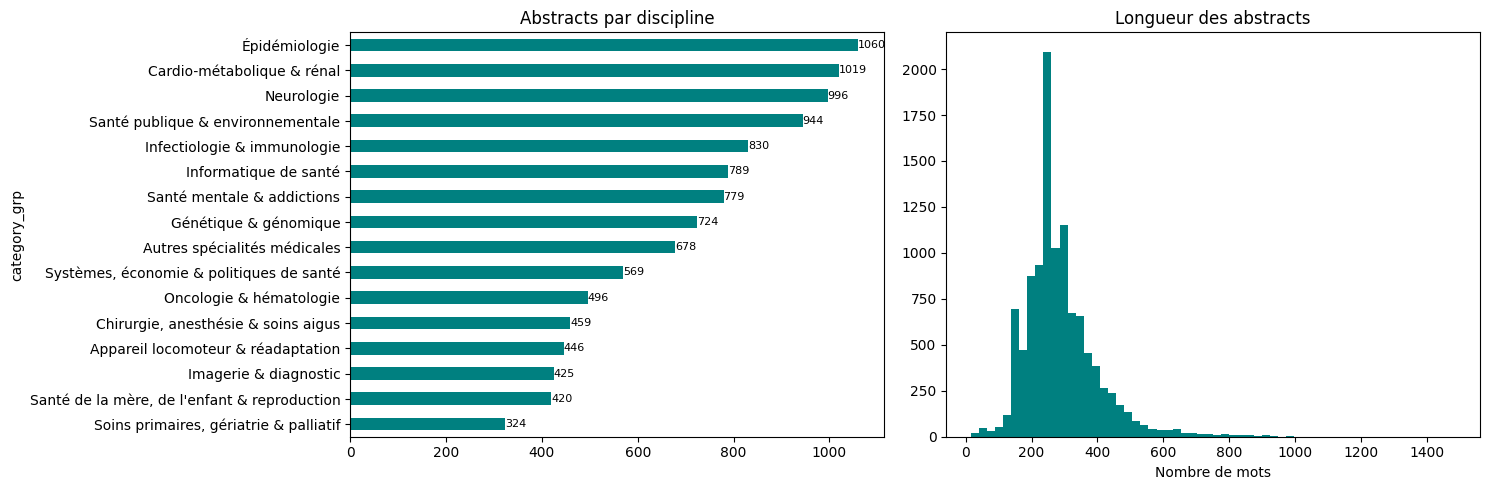

In [3]:
df = pd.read_csv(fichier_entrainement, sep=";")
df_test = pd.read_csv(fichier_test, sep=";")
print("Entraînement :", df.shape, "| test :", df_test.shape, "| valeurs manquantes (entraînement) :", df.isna().sum().sum())

#effectif de chaque discipline
effectifs = df[cible].value_counts()
print(f"\n{df[cible].nunique()} disciplines (regroupant {df['category'].nunique()} disciplines déclarées), de {effectifs.min()} à {effectifs.max()} abstracts")

#doublons : versions successives d'un même preprint (même doi) ou textes identiques
print("doi répétés :", df["doi"].duplicated().sum(), "| abstracts répétés :", df["abstract"].duplicated().sum(),
      "| abstracts identiques avec 2 disciplines :", (df.groupby("abstract")[cible].nunique() > 1).sum())

#longueur des abstracts en mots, et abstracts vides du fichier de test
df["n_mots"] = df["abstract"].str.split().str.len()
print("Mots par abstract : médiane", df["n_mots"].median(), "| min", df["n_mots"].min(), "| max", df["n_mots"].max())
print(f"Test : {df_test['abstract'].isna().sum()} abstracts vides ({100 * df_test['abstract'].isna().mean():.0f} %)")

#figure : effectifs par discipline et longueur des abstracts
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(15, 5))
effectifs.sort_values().plot(kind="barh", ax=ax_g, color="teal", title="Abstracts par discipline")
ax_g.bar_label(ax_g.containers[0], fontsize=8)
ax_d.hist(df["n_mots"], bins=60, color="teal")
ax_d.set(xlabel="Nombre de mots", title="Longueur des abstracts")
plt.tight_layout()
plt.show()

**Ce qu'on retient**
* Les classes sont déséquilibrées (de 324 à 1 060 abstracts, rapport de 1 à 3). Avec le F1 macro, chaque discipline compte autant, il faudra donc traiter ce déséquilibre (partie 5).
* L'étiquette est choisie par l'auteur au dépôt. Elle est donc subjective et bruitée.
* Environ 15 % des lignes sont répétées (versions successives d'un preprint). On les enlève en partie 2 et on mesure leur effet en partie 3.
* Un tiers des abstracts du test sont vides, il faudra leur donner une discipline par défaut (partie 7).

## 2. nettoyage et prétraitement
### 2.1 nettoyage des textes
* **Doublons :** on garde la dernière version de chaque preprint (même doi), puis un seul exemplaire de chaque texte. Les abstracts à deux étiquettes disparaissent au passage.
* **Manuscrits retirés :** 26 abstracts remplacés par une déclaration de retrait, sans contenu médical, sont enlevés.
* **Bruit du scraping :** on retire les entités HTML (signe ≥ écrit en code HTML), les balises de mise en page de medRxiv (`O_FIG`, `C_LIO_LI`, `O_SCPLOW`...), les liens de figures, les adresses web et les symboles `{beta}`, et on sépare les titres collés au texte (« ResultsWe found »).

On garde une copie des données brutes (`df_brut`) pour mesurer l'effet des doublons en partie 3.

In [4]:
def nettoyer_texte(texte):
    #nettoie un abstract brut, un abstract absent (NaN) devient une chaîne vide
    if not isinstance(texte, str):
        return ""
    texte = html.unescape(texte)                                         #entités HTML
    texte = re.sub(r"[OC]_SCPLOW", "", texte)                            #petites capitales (le mot est recollé)
    texte = re.sub(r"[OCM]_(?:LINKSMALLFIG|TABLECAPTION|FLOATNO|ST_ABS|TEXTBOX|FIG|TBL|LI)", " ", texte)  #mise en page
    texte = re.sub(r"\S*DTLVardef\S*|\S*HPS_FORMAT\S*|WIDTH=\d+|HEIGHT=\d+|SRC=\S+|ALT=\"[^\"]*\">?", " ", texte)  #figures
    texte = re.sub(r"View larger version \(\d+K\):?|https?://\S+|www\.\S+", " ", texte)   #liens
    texte = re.sub(r"\{[a-zA-Z]+\}", " ", texte)                         #symboles {beta}, {rho}...
    texte = re.sub(r"([a-z])([A-Z][a-z])", r"\1 \2", texte)              #titres collés au texte
    return re.sub(r"\s+", " ", texte).strip()


df_brut = df.copy()   #données brutes, gardées pour la partie 3

#doublons, puis manuscrits retirés
df = df.sort_values("date").drop_duplicates("doi", keep="last").drop_duplicates("abstract", keep="last")
df = df[~df["abstract"].str.match(r"\s*Withdrawal statement", case=False)].reset_index(drop=True)
df["texte"] = df["abstract"].map(nettoyer_texte)
print(f"{len(df_brut)} lignes au départ, {len(df)} abstracts conservés")

#contrôle sur un abstract qui contenait une figure
cas = df[df["abstract"].str.contains("O_FIG")].iloc[0]
print("\nBrut (fin) :", cas["abstract"][-300:])
print("\nNettoyé (fin) :", cas["texte"][-150:])

10958 lignes au départ, 9298 abstracts conservés

Brut (fin) :  Abstract

O_FIG O_LINKSMALLFIG WIDTH=200 HEIGHT=123 SRC="FIGDIR/small/26347229v1_ufig1.gif" ALT="Figure 1">
View larger version (41K):
org.highwire.dtl.DTLVardef@1d78db8org.highwire.dtl.DTLVardef@995b29org.highwire.dtl.DTLVardef@301b86org.highwire.dtl.DTLVardef@5f1427_HPS_FORMAT_FIGEXP  M_FIG C_FIG

Nettoyé (fin) :  provide a novel approach for automated, accurate, and rapid diagnosis of MVP and its common clinical sequelae across institutions. Graphical Abstract


### 2.2 prétraitement linguistique
Avec spaCy, on fait la **tokenisation**, on passe en **minuscules**, on fait la **lemmatisation** (« studies » devient « study ») et on retire les **mots vides**, la ponctuation et les nombres. La lemmatisation utilise une table de correspondance (`spacy-lookups-data`) qui donne la forme de base de chaque mot sans regarder la phrase. Elle est beaucoup plus rapide que le modèle complet `en_core_web_sm`, pour le même score, au prix de rares erreurs (« rebound » devient « rebind »). Les sigles avec chiffres (« covid-19 », « hiv-1 ») sont gardés. Chaque texte est traité seul, sans rien estimer sur l'ensemble des données, donc il n'y a pas de fuite d'information.

In [ ]:
import spacy
from sklearn.feature_extraction.text import CountVectorizer

nlp = spacy.blank("en")                                    #tokeniseur anglais de spaCy
nlp.add_pipe("lemmatizer", config={"mode": "lookup"})      #lemmatisation par table de correspondance 
nlp.initialize()


def pretraiter(textes):
    #lemmes en minuscules, sans mots vides, ponctuation, espaces ni nombres
    resultat = []
    for doc in nlp.pipe(textes, batch_size=500):
        resultat.append(" ".join(t.lemma_.lower() for t in doc
                                 if not (t.is_stop or t.is_punct or t.is_space or t.like_num)))
    return resultat


t0 = time.time()
df["lemmes"] = pretraiter(df["texte"])
print(f"Lemmatisation : {time.time() - t0:.0f} s")

#vérification avant/après et taille du vocabulaire
print("\nAvant :", " ".join(df["texte"][0].split()[:25]))
print("Après :", " ".join(df["lemmes"][0].split()[:18]))
for colonne in ["texte", "lemmes"]:
    compteur = CountVectorizer().fit(df[colonne])
    print(f"{colonne} : {len(compteur.vocabulary_)} mots différents, "
          f"{compteur.transform(df[colonne]).sum(axis=1).mean():.0f} mots par abstract")

Lemmatisation : 33 s

Avant : HIV-1 persists during antiretroviral therapy (ART), resulting in rebound viremia after treatment interruption. HIV-specific CD8+ T cell functionality is typically not restored by ART but
Après : hiv-1 persist antiretroviral therapy art result rebind viremia treatment interruption hiv specific cd8 + t cell functionality typically
texte : 52735 mots différents, 297 mots par abstract
lemmes : 46340 mots différents, 197 mots par abstract


## 3. stratégie de validation
La validation se fait sur le jeu d'entraînement seul, par **validation croisée stratifiée à 5 plis**. Les abstracts sont coupés en 5 parts qui gardent la proportion de chaque discipline, le modèle apprend sur 4 parts et il est évalué sur la 5e, 5 fois de suite. Le score d'un modèle est la moyenne des 5 F1 macro, et leur écart-type montre la variabilité d'un pli à l'autre. Les mêmes plis servent à tous les choix (représentation, déséquilibre, hyperparamètres, modèle final).

Tout ce qui est appris sur les données (vocabulaire TF-IDF, LSA, chi2) est dans un `Pipeline`, donc à chaque pli il ne voit que la partie apprentissage.

**Pourquoi enlever les doublons ?** On mesure le F1 macro d'un même modèle simple (TF-IDF + SVM linéaire) sur les données brutes, puis sur les données nettoyées. Avec les doublons, un abstract évalué a souvent une autre version de lui-même dans la partie apprentissage.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

X, y = df[["texte", "lemmes"]], df[cible]
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   #mêmes 5 plis pour toute la suite

#effet des doublons : même modèle simple, données brutes puis données sans doublons
modele_simple = make_pipeline(TfidfVectorizer(min_df=2, stop_words="english", sublinear_tf=True),
                              LinearSVC(C=0.5, class_weight="balanced"))
for nom, donnees in [("avec doublons", df_brut), ("sans doublons", df)]:
    f1 = cross_val_score(modele_simple, donnees["abstract"].map(nettoyer_texte), donnees[cible],
                         cv=plis, scoring="f1_macro", n_jobs=-1).mean()
    print(f"F1 macro {nom} : {f1:.3f}")

F1 macro avec doublons : 0.680
F1 macro sans doublons : 0.567


Avec les doublons, le F1 macro monte à 0,680 contre 0,567 sans. Le modèle reconnaît une autre version d'un abstract déjà vu, ce score serait donc trompeur. D'où la suppression des doublons.

## 4. représentations du texte et réduction de dimension
### 4.1 représentations du texte
| Représentation | Principe |
|---|---|
| sac de mots | présence (1) ou absence (0) de chaque mot |
| TF-IDF mots | fréquence du mot dans l'abstract × rareté dans le corpus |
| TF-IDF n-grammes de mots | mots + paires de mots consécutifs (« heart failure ») |
| TF-IDF n-grammes de caractères | suites de 3 à 5 caractères (les 50 000 plus fréquentes) |

Le TF-IDF utilise `min_df=2` (mot vu dans au moins 2 abstracts), `max_df=0.5` (mot présent dans moins de la moitié des abstracts) et `sublinear_tf=True` (1 + log de la fréquence).

On utilise le même SVM linéaire pondéré pour toutes les représentations, et on compare leur F1 macro en validation croisée. On retient celle qui a le meilleur F1 macro moyen. On mesure aussi l'apport de la lemmatisation (même TF-IDF sur le texte non lemmatisé).

In [ ]:
import os
import warnings
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from joblib import Memory

warnings.filterwarnings("ignore")          #avertissements de convergence masqués
os.environ["PYTHONWARNINGS"] = "ignore"    #idem dans les calculs en parallèle


def tfidf(colonne, **reglages):
    #TF-IDF appliqué à une seule colonne de X (lemmes ou texte)
    return ColumnTransformer([("tfidf", TfidfVectorizer(min_df=2, max_df=0.5, sublinear_tf=True, **reglages), colonne)])


def f1_vc(pipeline):
    #F1 macro en validation croisée : moyenne et écart-type sur les 5 plis
    scores = cross_val_score(pipeline, X, y, cv=plis, scoring="f1_macro", n_jobs=-1)
    return scores.mean(), scores.std()


svm = lambda: LinearSVC(C=0.5, class_weight="balanced", max_iter=5000)   #classifieur de comparaison
cache = Memory("cache_tfidf", verbose=0)   #mémorise les TF-IDF déjà calculés sur les mêmes abstracts 

representations = {
    "sac de mots": ColumnTransformer([("sac", CountVectorizer(min_df=2, max_df=0.5, binary=True), "lemmes")]),
    "TF-IDF mots": tfidf("lemmes"),
    "TF-IDF n-grammes de mots (1-2)": tfidf("lemmes", ngram_range=(1, 2)),
    "TF-IDF n-grammes de caractères (3-5)": tfidf("texte", analyzer="char_wb", ngram_range=(3, 5), max_features=50000),
}
lignes_rep = []
for nom, rep in representations.items():
    moyenne, ecart = f1_vc(make_pipeline(rep, svm(), memory=cache))
    lignes_rep.append((nom, moyenne, ecart))
    print(f"{nom} : F1 macro = {moyenne:.3f} (écart-type {ecart:.3f})", flush=True)   #affiché dès que c'est calculé
comparaison = pd.DataFrame(lignes_rep, columns=["représentation", "F1 macro", "écart-type"]).set_index("représentation")

#représentation retenue : meilleur F1 macro moyen
nom_rep = comparaison["F1 macro"].idxmax()
rep_choisie = representations[nom_rep]
print("\nReprésentation retenue :", nom_rep)

#apport de la lemmatisation : TF-IDF n-grammes de mots sur le texte non lemmatisé (mots vides retirés par scikit-learn)
sans_lemmes = tfidf("texte", stop_words="english", ngram_range=(1, 2))
print(f"TF-IDF n-grammes de mots sans lemmatisation : F1 macro = {f1_vc(make_pipeline(sans_lemmes, svm()))[0]:.3f}")

sac de mots : F1 macro = 0.465 (écart-type 0.011)
TF-IDF mots : F1 macro = 0.565 (écart-type 0.014)
TF-IDF n-grammes de mots (1-2) : F1 macro = 0.577 (écart-type 0.018)
TF-IDF n-grammes de caractères (3-5) : F1 macro = 0.561 (écart-type 0.012)

Représentation retenue : TF-IDF n-grammes de mots (1-2)
TF-IDF n-grammes de mots sans lemmatisation : F1 macro = 0.577


* Le TF-IDF bat nettement le sac de mots (0,565 contre 0,465). Pondérer les mots par leur rareté aide beaucoup.
* Les paires de mots donnent le meilleur score (0,577), devant les n-grammes de caractères (0,561) et les mots seuls (0,565). C'est la représentation retenue.
* La lemmatisation ne change pas le score (0,577 avec et sans), elle réduit surtout le vocabulaire.

### 4.2 réduction de la dimensionnalité
Le TF-IDF compte des dizaines de milliers de variables, presque toutes nulles, et random forest et gradient boosting (partie 5) y sont lents et peu efficaces. On teste donc deux façons de réduire le nombre de variables.
* le **chi2**, qui garde les k termes les plus liés à la discipline (test du chi2)
* la **LSA** (SVD tronquée), qui remplace les termes par quelques centaines de composantes regroupant les mots employés ensemble

On regarde les termes retenus par le chi2, puis ce que chaque réduction fait perdre au SVM linéaire.

In [8]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import TruncatedSVD

#chi2 : les 15 termes les plus liés à la discipline
modele_tfidf = clone(rep_choisie).fit(X)
termes = np.array([n.split("__", 1)[-1] for n in modele_tfidf.get_feature_names_out()])
score_chi2 = chi2(modele_tfidf.transform(X), y)[0]
print("Termes les plus liés à la discipline :", ", ".join(termes[np.argsort(score_chi2)[::-1][:15]]))

#SVM linéaire après réduction
for nom, reduction in [("chi2, 3 000 termes", SelectKBest(chi2, k=3000)),
                       ("LSA, 100 composantes", TruncatedSVD(n_components=100, random_state=42))]:
    print(f"SVM linéaire après {nom} : F1 macro = {f1_vc(make_pipeline(clone(rep_choisie), reduction, svm(), memory=cache))[0]:.3f}", flush=True)

Termes les plus liés à la discipline : variant, genetic, tumor, locus, cancer, gene, gwas, pain, genome, genome wide, infection, ancestry, hiv, image, tb
SVM linéaire après chi2, 3 000 termes : F1 macro = 0.557
SVM linéaire après LSA, 100 composantes : F1 macro = 0.515


Les termes retenus par le chi2 ont un sens médical clair (variant, tumor, cancer, hiv, tb...). Mais pour un modèle linéaire, réduire fait perdre du F1 macro (0,577 sans réduction, 0,557 avec chi2, 0,515 avec la LSA à 100 composantes). On garde donc le TF-IDF complet pour les modèles linéaires et on réserve chi2 et LSA au random forest et au gradient boosting.

## 5. modèles
### 5.1 déséquilibre des classes
Trois solutions sont comparées à l'absence de correction (même TF-IDF et même SVM) :
* la **pondération** (`class_weight="balanced"`), où une erreur sur une discipline rare coûte plus cher
* le **sous-échantillonnage**, qui retire au hasard des abstracts des grandes disciplines
* le **sur-échantillonnage**, qui duplique au hasard des abstracts des petites disciplines

Le pipeline d'`imbalanced-learn` ne ré-échantillonne que la partie apprentissage de chaque pli.

In [9]:
from imblearn.pipeline import make_pipeline as make_pipeline_imb
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

sans_poids = lambda: LinearSVC(C=0.5, max_iter=5000)
for nom, etapes in [("aucune correction", [sans_poids()]),
                    ("pondération", [svm()]),
                    ("sous-échantillonnage", [RandomUnderSampler(random_state=42), sans_poids()]),
                    ("sur-échantillonnage", [RandomOverSampler(random_state=42), sans_poids()])]:
    print(f"{nom} : F1 macro = {f1_vc(make_pipeline_imb(clone(rep_choisie), *etapes, memory=cache))[0]:.3f}")

aucune correction : F1 macro = 0.565
pondération : F1 macro = 0.577
sous-échantillonnage : F1 macro = 0.538
sur-échantillonnage : F1 macro = 0.577


La pondération et le sur-échantillonnage donnent le meilleur score (0,577), devant l'absence de correction (0,565). Le sous-échantillonnage est le moins bon (0,538) car il jette des abstracts. **On retient la pondération**, à égalité avec le sur-échantillonnage, car elle ne duplique aucun abstract et elle est disponible directement dans les modèles.

### 5.2 les cinq modèles de classification
| Modèle | Principe | Réglage testé (recherche sur grille) |
|---|---|---|
| régression logistique | combinaison linéaire des termes, transformée en probabilités | C = 3 / 10 |
| Naive Bayes (`ComplementNB`) | probabilités des mots par discipline, version prévue pour les classes déséquilibrées | alpha = 0,03 / 0,1 / 0,3 |
| SVM linéaire | frontière linéaire de marge maximale | C = 0,3 / 1 / 3 |
| random forest | 100 arbres qui votent, après sélection chi2 de 3 000 termes | fixé (min_samples_leaf = 2) |
| gradient boosting | 50 arbres ajoutés un à un pour corriger les erreurs, après LSA | fixé (100 composantes LSA) |

C est l'**hyperparamètre de régularisation** (plus il est grand, moins le modèle est régularisé et plus il risque de surapprendre), alpha le lissage de Naive Bayes et min_samples_leaf le nombre minimum d'abstracts par feuille.

Naive Bayes et le SVM, rapides, sont réglés par recherche sur grille (`GridSearchCV`, mêmes 5 plis, meilleur F1 macro). La régression logistique utilise le solveur `saga`, beaucoup plus rapide que celui par défaut sur des milliers de variables, et elle est réglée par recherche sur grille comme eux. Random forest et gradient boosting, très lents, ont un réglage fixé pour limiter le temps de calcul. Tous les modèles qui l'acceptent utilisent la pondération des classes. 

In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

grilles = {
    #solveur saga, beaucoup plus rapide que celui par défaut sur des milliers de variables creuses
    "Régression logistique": (make_pipeline(clone(rep_choisie), LogisticRegression(class_weight="balanced", solver="saga",
                                                                                   max_iter=200, tol=1e-3), memory=cache),
                              {"logisticregression__C": [3, 10]}),
    "Naive Bayes": (make_pipeline(clone(rep_choisie), ComplementNB(), memory=cache),
                    {"complementnb__alpha": [0.03, 0.1, 0.3]}),
    "SVM linéaire": (make_pipeline(clone(rep_choisie), LinearSVC(class_weight="balanced", max_iter=5000), memory=cache),
                     {"linearsvc__C": [0.3, 1, 3]}),
    #random forest et gradient boosting, beaucoup plus lents, réglage fixé (une seule valeur)
    "Random forest": (make_pipeline(clone(rep_choisie), SelectKBest(chi2, k=3000),
                                    RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=42),
                                    memory=cache),
                      {"randomforestclassifier__min_samples_leaf": [2]}),
    "Gradient boosting": (make_pipeline(clone(rep_choisie), TruncatedSVD(random_state=42),
                                        HistGradientBoostingClassifier(max_iter=50, early_stopping=True,
                                                                       class_weight="balanced", random_state=42),
                                        memory=cache),
                          {"truncatedsvd__n_components": [100]}),
}

modeles, lignes = {}, []
for nom, (pipeline, grille) in grilles.items():
    print(f"{nom} en cours...", flush=True)       #pour suivre l'avancement
    t0 = time.time()
    recherche = GridSearchCV(pipeline, grille, cv=plis, scoring={"f1": "f1_macro", "exactitude": "accuracy"},
                             refit="f1", n_jobs=-1).fit(X, y)
    modeles[nom] = recherche.best_estimator_     #meilleur réglage, réappris sur tous les abstracts
    resultats = recherche.cv_results_
    i = recherche.best_index_
    lignes.append({"modèle": nom, "F1 macro": resultats["mean_test_f1"][i], "écart-type": resultats["std_test_f1"][i],
                   "exactitude": resultats["mean_test_exactitude"][i]})
    print(f"{nom} : {recherche.best_params_} | F1 macro = {resultats['mean_test_f1'][i]:.3f} | {time.time() - t0:.0f} s", flush=True)

Régression logistique en cours...
Régression logistique : {'logisticregression__C': 10} | F1 macro = 0.569 | 125 s
Naive Bayes en cours...
Naive Bayes : {'complementnb__alpha': 0.1} | F1 macro = 0.535 | 25 s
SVM linéaire en cours...
SVM linéaire : {'linearsvc__C': 1} | F1 macro = 0.575 | 62 s
Random forest en cours...
Random forest : {'randomforestclassifier__min_samples_leaf': 2} | F1 macro = 0.510 | 52 s
Gradient boosting en cours...
Gradient boosting : {'truncatedsvd__n_components': 100} | F1 macro = 0.490 | 211 s


Les modèles linéaires dominent (SVM 0,575, régression logistique 0,569, Naive Bayes 0,535). Random forest (0,510) et gradient boosting (0,490) restent en dessous malgré la réduction de dimension. Le meilleur réglage de la régression logistique tombe au bord de sa grille (C = 10), mais C = 30 et C = 100, testés lors d'essais précédents, faisaient moins bien. Le gradient boosting est le plus lent des cinq.

### 5.3 super-learner
Les modèles de base produisent, en validation croisée, leurs scores pour les 16 disciplines sur des abstracts qu'ils n'ont pas appris. Une régression logistique (méta-modèle) apprend ensuite à combiner ces scores. Les modèles combinés sont Naive Bayes (modèle probabiliste) et le SVM linéaire (marge maximale), rapides et de principes différents. La régression logistique est laissée de côté car elle ressemble beaucoup au SVM (deux modèles linéaires sur les mêmes mots) et elle est beaucoup plus lente à réentraîner. Random forest et gradient boosting sont écartés car ils sont moins bons et très lents. Pour aller plus vite, le stacking utilise 3 plis internes au lieu de 5, il réapprend donc chaque modèle 4 fois au lieu de 6.

In [11]:
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score

bases = [(nom, modeles[nom]) for nom in ["Naive Bayes", "SVM linéaire"]]   #deux modèles rapides et de principes différents
#3 plis internes (au lieu de 5) pour produire les scores des modèles de base, plus rapide
plis_internes = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
modeles["Super-learner"] = StackingClassifier(bases, final_estimator=LogisticRegression(max_iter=2000), cv=plis_internes)

#évaluation avec les mêmes 5 plis : probabilités de chaque abstract par un super-learner appris sans lui
proba_sl = cross_val_predict(modeles["Super-learner"], X, y, cv=plis, n_jobs=-1, method="predict_proba")
pred_sl = np.array(sorted(y.unique()))[proba_sl.argmax(axis=1)]   #discipline la plus probable
f1_plis = [f1_score(y.iloc[test], pred_sl[test], average="macro") for _, test in plis.split(X, y)]
lignes.append({"modèle": "Super-learner", "F1 macro": np.mean(f1_plis), "écart-type": np.std(f1_plis),
               "exactitude": accuracy_score(y, pred_sl)})
print(f"Super-learner : F1 macro = {np.mean(f1_plis):.3f}")

Super-learner : F1 macro = 0.577


## 6. évaluation et analyse des erreurs
### 6.1 comparaison des modèles
Tous les modèles sont évalués avec les mêmes 5 plis. Le point de comparaison est un tirage au hasard selon les fréquences des disciplines (`DummyClassifier`). **Le modèle final est celui qui a le meilleur F1 macro moyen.**

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

#référence : tirage au hasard
hasard = cross_validate(DummyClassifier(strategy="stratified", random_state=42), X, y, cv=plis,
                        scoring={"f1": "f1_macro", "exactitude": "accuracy"})
lignes.append({"modèle": "Hasard (référence)", "F1 macro": hasard["test_f1"].mean(),
               "écart-type": hasard["test_f1"].std(), "exactitude": hasard["test_exactitude"].mean()})

performances = pd.DataFrame(lignes).set_index("modèle").sort_values("F1 macro", ascending=False)
nom_final = performances.index[0]
print("Modèle final :", nom_final)
performances.round(3)

Modèle final : Super-learner


,F1 macro,écart-type,exactitude
modèle,,,
Super-learner,0.577,0.017,0.590
SVM linéaire,0.575,0.018,0.591
Régression logistique,0.569,0.016,0.586
Naive Bayes,0.535,0.014,0.571
Random forest,0.510,0.008,0.530
Gradient boosting,0.490,0.006,0.517
Hasard (référence),0.063,0.005,0.073


* Le **super-learner** (0,577) et le **SVM linéaire** (0,575) sont en tête, à égalité (écart de 0,002 pour un écart-type d'environ 0,02 entre plis). Le super-learner est retenu car il a la meilleure moyenne, mais le SVM seul ferait aussi bien. Combiner Naive Bayes et le SVM n'apporte presque rien ici.
* L'exactitude du super-learner est de 0,590. Tous les modèles sont très loin du hasard (0,063), et random forest et gradient boosting restent les moins bons.

### 6.2 analyse des erreurs du modèle final
On analyse les prédictions de validation croisée du modèle final (chaque abstract est prédit par un modèle qui ne l'a pas appris) avec la matrice de confusion en % de chaque ligne (la diagonale est le rappel), le F1 par discipline, la part d'abstracts dont la bonne discipline est parmi les 1, 2 ou 3 premières propositions du modèle, et les confusions les plus fréquentes. Les termes de plus grand poids vérifient ensuite que le modèle s'appuie sur un vocabulaire médical cohérent.

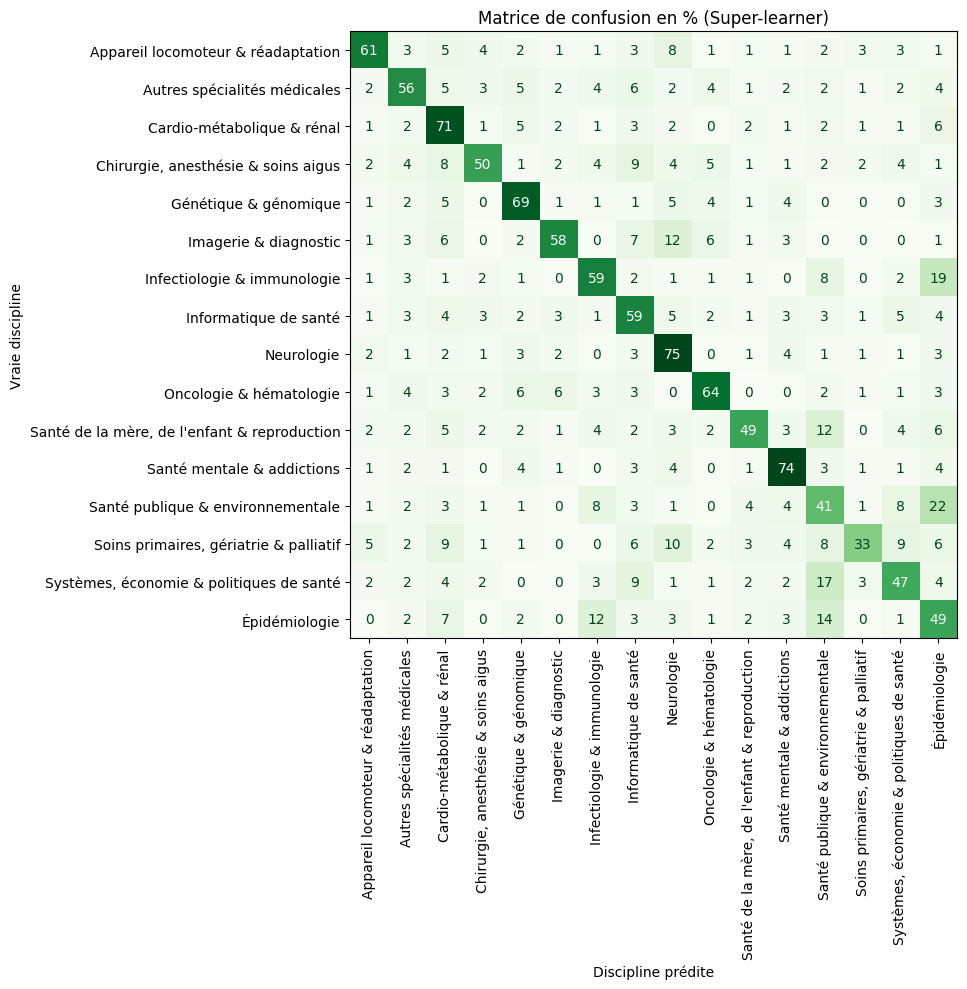

F1 par discipline :
Neurologie                                      0.72
Santé mentale & addictions                      0.72
Cardio-métabolique & rénal                      0.68
Génétique & génomique                           0.68
Oncologie & hématologie                         0.65
Appareil locomoteur & réadaptation              0.62
Imagerie & diagnostic                           0.60
Infectiologie & immunologie                     0.60
Autres spécialités médicales                    0.58
Informatique de santé                           0.57
Santé de la mère, de l'enfant & reproduction    0.52
Chirurgie, anesthésie & soins aigus             0.52
Systèmes, économie & politiques de santé        0.49
Épidémiologie                                   0.47
Santé publique & environnementale               0.42
Soins primaires, gériatrie & palliatif          0.40
Bonne discipline parmi les 1 premières propositions : 59 %
Bonne discipline parmi les 2 premières propositions : 79 %
Bonne discipli

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#scores de validation croisée du modèle final (une colonne par discipline, dans l'ordre alphabétique)
disciplines = sorted(y.unique())
if nom_final == "Super-learner":
    scores_final = proba_sl
else:
    methode = "decision_function" if hasattr(modeles[nom_final], "decision_function") else "predict_proba"
    scores_final = cross_val_predict(modeles[nom_final], X, y, cv=plis, n_jobs=-1, method=methode)
pred_final = np.array(disciplines)[scores_final.argmax(axis=1)]
confusion = confusion_matrix(y, pred_final, labels=disciplines)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(100 * confusion / confusion.sum(axis=1, keepdims=True), display_labels=disciplines).plot(
    ax=ax, cmap="Greens", colorbar=False, values_format=".0f", xticks_rotation=90)
ax.set(xlabel="Discipline prédite", ylabel="Vraie discipline", title=f"Matrice de confusion en % ({nom_final})")
plt.tight_layout()
plt.show()

#F1 par discipline et confusions les plus fréquentes
f1_disc = pd.Series(f1_score(y, pred_final, average=None, labels=disciplines), index=disciplines)
print("F1 par discipline :\n" + f1_disc.sort_values(ascending=False).round(2).to_string())

#la bonne discipline est-elle parmi les 1, 2 ou 3 premières propositions du modèle ?
rangs = np.argsort(-scores_final, axis=1)          #disciplines classées de la plus à la moins probable
vraie = np.searchsorted(disciplines, y)            #numéro de la vraie discipline
for k in (1, 2, 3):
    print(f"Bonne discipline parmi les {k} premières propositions : {100 * (rangs[:, :k] == vraie[:, None]).any(axis=1).mean():.0f} %")
paires = pd.DataFrame(confusion, index=disciplines, columns=disciplines).stack()
paires = paires[[vraie != predite for vraie, predite in paires.index]]
print("\nConfusions les plus fréquentes (vraie, prédite, nombre) :\n" + paires.nlargest(6).to_string())

In [14]:
#termes de plus grand poids pour chaque discipline (modèle final s'il est linéaire, sinon régression logistique)
lineaire = modeles[nom_final if nom_final in ("Régression logistique", "SVM linéaire") else "Régression logistique"]
noms = np.array([n.split("__", 1)[-1] for n in lineaire[0].get_feature_names_out()])
pd.set_option("display.max_colwidth", None)
pd.DataFrame({"termes caractéristiques": [", ".join(noms[np.argsort(c)[::-1][:6]]) for c in lineaire[-1].coef_]},
             index=lineaire[-1].classes_)

,termes caractéristiques
Appareil locomoteur & réadaptation,"pain, rehabilitation, fracture, exercise, ra, athlete"
Autres spécialités médicales,"eye, glaucoma, dental, ocular, tooth, oral"
Cardio-métabolique & rénal,"cardiovascular, food, cardiac, heart, dietary, kidney"
"Chirurgie, anesthésie & soins aigus","sepsis, postoperative, surgical, icu, surgery, emergency"
Génétique & génomique,"genetic, variant, gene, locus, genome, polygenic"
Imagerie & diagnostic,"image, ct, mri, radiologist, scan, radiology"
Infectiologie & immunologie,"hiv, infection, tb, viral, transmission, virus"
Informatique de santé,"clinical, ehr, record, prediction, feature, ai"
Neurologie,"stroke, pd, brain, seizure, dementia, parkinsons"
Oncologie & hématologie,"cancer, tumor, survival, patient, cell, chemotherapy"


* Les disciplines centrées sur un organe ou une maladie sont bien reconnues, comme la neurologie et la santé mentale (F1 de 0,72), le cardio-métabolique et la génétique (0,68).
* Les moins bien reconnues sont transversales, comme les soins primaires & gériatrie (0,40), la santé publique (0,42), l'épidémiologie (0,47) et les systèmes de santé (0,49). Les confusions les plus fréquentes sont entre elles (santé publique et épidémiologie, infectiologie et épidémiologie). Une étude sur la transmission d'une infection peut légitimement être déposée dans l'une ou l'autre, donc une partie de ces « erreurs » vient de l'étiquetage.
* Quand le modèle se trompe, il n'est souvent pas loin. La bonne discipline est sa 1re proposition pour 59 % des abstracts, parmi ses 2 premières pour 79 % et parmi ses 3 premières pour 88 %. Pour suggérer des disciplines à un auteur au moment du dépôt, le modèle serait donc utile.
* Le super-learner n'a pas de coefficients par mot, les termes caractéristiques viennent donc de la régression logistique. Ils sont cohérents (« stroke », « seizure », « parkinsons » en neurologie, « hiv », « tb » en infectiologie, « ehr », « ai » en informatique de santé). Ceux d'« Autres spécialités médicales » mélangent ophtalmologie et dentaire, car ce groupe n'a pas de vocabulaire commun.

## 7. prédiction du fichier de test
* Le modèle final est appris sur tous les abstracts étiquetés.
* Le fichier de test passe par les mêmes fonctions `nettoyer_texte` et `pretraiter`.
* Les abstracts vides ou presque (moins de 3 mots après prétraitement) n'ont aucune information, ils reçoivent donc la discipline la plus fréquente du jeu d'entraînement.
* Le code vérifie le fichier de test (colonne `abstract`, ID uniques) puis le fichier rendu (colonnes `ID` et `pred`, une ligne par abstract, libellés exacts) avant de l'écrire.

In [15]:
#modèle final appris sur tous les abstracts (le super-learner n'a été appris que dans la validation croisée)
modele_final = modeles[nom_final].fit(X, y) if nom_final == "Super-learner" else modeles[nom_final]

#vérification du fichier de test
assert "abstract" in df_test.columns, "le fichier de test doit avoir une colonne abstract"
assert "ID" not in df_test.columns or df_test["ID"].is_unique, "les ID du fichier de test doivent être uniques"

#nettoyage, prétraitement et prédiction du fichier de test
df_test["texte"] = df_test["abstract"].map(nettoyer_texte)
df_test["lemmes"] = pretraiter(df_test["texte"])
trop_court = (df_test["lemmes"].str.split().str.len() < 3).to_numpy()
defaut = y.value_counts().idxmax()
pred = np.where(trop_court, defaut, modele_final.predict(df_test[["texte", "lemmes"]]))

#fichier rendu (numérotation à partir de 1 si le fichier n'a pas d'ID), vérifié avant d'être écrit
identifiants = df_test["ID"] if "ID" in df_test.columns else pd.RangeIndex(1, len(df_test) + 1)
sortie = pd.DataFrame({"ID": identifiants, "pred": pred})
assert list(sortie.columns) == ["ID", "pred"] and len(sortie) == len(df_test), "format du fichier rendu incorrect"
assert sortie["pred"].isin(disciplines).all(), "une prédiction n'est pas un libellé du jeu d'entraînement"
sortie.to_csv(fichier_sortie, index=False)
print(f"{len(sortie)} prédictions dans {fichier_sortie}, dont {trop_court.sum()} abstracts vides ou presque ({defaut}), format vérifié")
cache.clear()   #efface les TF-IDF mémorisés (environ 150 Mo sur le disque)

1940 prédictions dans predictions_projet1.csv, dont 645 abstracts vides ou presque (Épidémiologie), format vérifié


## 8. conclusion

**Démarche**
* Nettoyage des balises du scraping et suppression des doublons (avec doublons, le score serait gonflé de 0,567 à 0,680), puis prétraitement spaCy (tokenisation, minuscules, mots vides, lemmatisation).
* Validation croisée stratifiée à 5 plis sur le jeu d'entraînement, utilisée pour tous les choix.
* Des comparaisons à chaque étape, pour les représentations (sac de mots, TF-IDF, n-grammes), la réduction de dimension (chi2, LSA) et le déséquilibre (pondération, sous- et sur-échantillonnage), puis cinq modèles réglés par recherche sur grille et un super-learner.

**Résultats**
* La représentation retenue est le TF-IDF des mots et paires de mots lemmatisés, avec pondération des classes.
* Le modèle final est le **super-learner (Naive Bayes + SVM linéaire), avec un F1 macro de 0,577** (exactitude 0,590), à égalité avec le SVM linéaire seul (0,575). Le hasard donne 0,063. La bonne discipline est parmi les 3 premières propositions du modèle pour 88 % des abstracts.
* Les modèles linéaires battent le random forest et le gradient boosting. Combiner les modèles n'apporte presque rien.
* Les disciplines liées à un organe ou une maladie sont bien reconnues (F1 de 0,68 à 0,72), les disciplines transversales beaucoup moins (0,40 à 0,49).

**Limites**
* L'étiquette est déclarée par les auteurs. Elle est subjective, et un même sujet peut relever de deux disciplines, ce qui limite le score atteignable.
* Une représentation par mots ignore les synonymes (« heart attack » et « myocardial infarction ») et l'ordre des mots.
* Un tiers des abstracts du test sont vides. Ils reçoivent la discipline la plus fréquente, ce qui fera baisser le F1 macro sur le test.